# 05 - Interpretabilità con SHAP

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Il notebook `04_confronto_modelli` ha identificato **XGBoost** come modello con l'AUC più alta
(0,869 sul test set). È anche il meno interpretabile "di default" dei tre: qui usiamo **SHAP**
(SHapley Additive exPlanations) per recuperare sia una spiegazione **globale** (quali variabili
contano di più, in media, su tutte le previsioni) sia **locale** (perché il modello ha dato *questa*
previsione a *questo* cliente specifico) — quest'ultima è spesso un requisito pratico, non solo
tecnico, nel credito al consumo.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import shap

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
RANDOM_SEED = 42

COLOR_SEQ = '#2a78d6'
COLOR_CRITICAL = '#d03b3b'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Dataset e riaddestramento del modello migliore

I notebook precedenti non hanno salvato gli oggetti-modello su disco, solo le predizioni: li
riproduciamo qui. Stesso dataset, stesse feature, stesso split (`random_state=42`, stratificato) e
stessa configurazione di XGBoost del notebook 04 — la stima è deterministica, quindi il modello
ottenuto è identico, non solo simile (lo verifichiamo confrontando l'AUC con quella già registrata:
0,8686).

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)
TARGET = 'SeriousDlqin2yrs'

FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
    'MonthlyIncome_mancante',
    'NumberOfDependents_mancante',
]

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)

xgb_model = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    eval_metric='auc', random_state=RANDOM_SEED, n_jobs=-1, importance_type='gain',
)
xgb_model.fit(X_train, y_train)

proba_test = xgb_model.predict_proba(X_test)[:, 1]
print(f"AUC test: {roc_auc_score(y_test, proba_test):.4f}  (atteso, dal notebook 04: 0.8686)")

AUC test: 0.8686  (atteso, dal notebook 04: 0.8686)


## 2. Calcolo dei valori SHAP

XGBoost è un modello ad albero: usiamo `shap.TreeExplainer`, esatto (non approssimato) e molto più
veloce del `KernelExplainer` generico per questa famiglia di modelli. (Se il modello migliore fosse
risultato la regressione logistica, avremmo usato `shap.LinearExplainer`, appropriato per modelli
lineari — non è questo il caso qui.)

**Dimensione del campione:** calcoliamo i valori SHAP su un campione casuale di **3.000** righe del
test set (seed fissato, riproducibile), non sull'intero test set (30.000 righe). In questo caso il
tempo di calcolo non è di fatto un problema — `TreeExplainer` impiega meno di un secondo per 3.000
righe, e sarebbe comunque rapido sull'intero test set — ma manteniamo un campione di questa
dimensione per due motivi: (1) restare nell'ordine di grandezza tipico usato in pratica per questo
tipo di analisi, e (2) il summary plot beeswarm diventa visivamente denso e poco leggibile con
troppi punti sovrapposti oltre poche migliaia di osservazioni.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
sample_idx = rng.choice(X_test.index, size=3000, replace=False)
X_sample = X_test.loc[sample_idx]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_sample)

print(f"Valori SHAP calcolati su {shap_values.values.shape[0]:,} righe x {shap_values.values.shape[1]} variabili")

Valori SHAP calcolati su 3,000 righe x 12 variabili


## 3. Interpretabilità globale

### Summary plot (beeswarm)

Ogni punto è un cliente; la posizione orizzontale è il valore SHAP (impatto sulla previsione in
log-odds, negativo = spinge verso "non insolvente", positivo verso "insolvente"), il colore è il
valore della variabile per quel cliente (rosso = alto, blu = basso), le variabili sono ordinate per
importanza media.

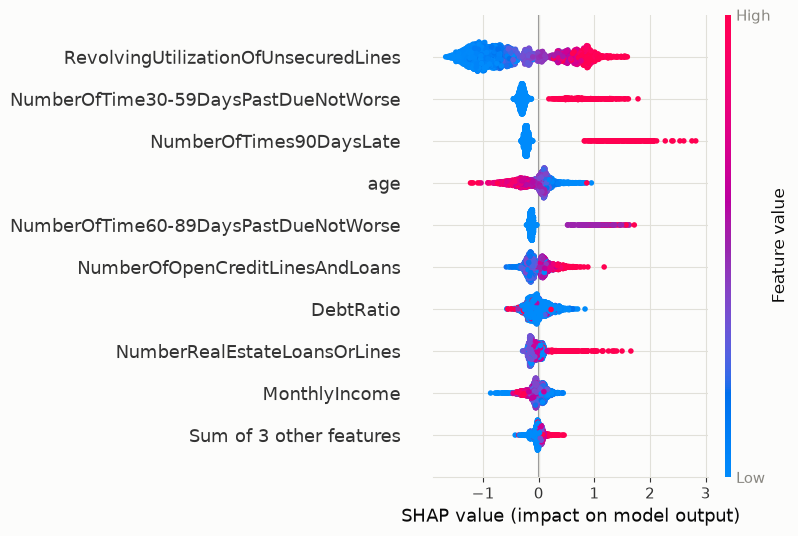

In [4]:
shap.plots.beeswarm(shap_values, show=False)
plt.tight_layout()
plt.show()

### Bar plot - importanza media assoluta

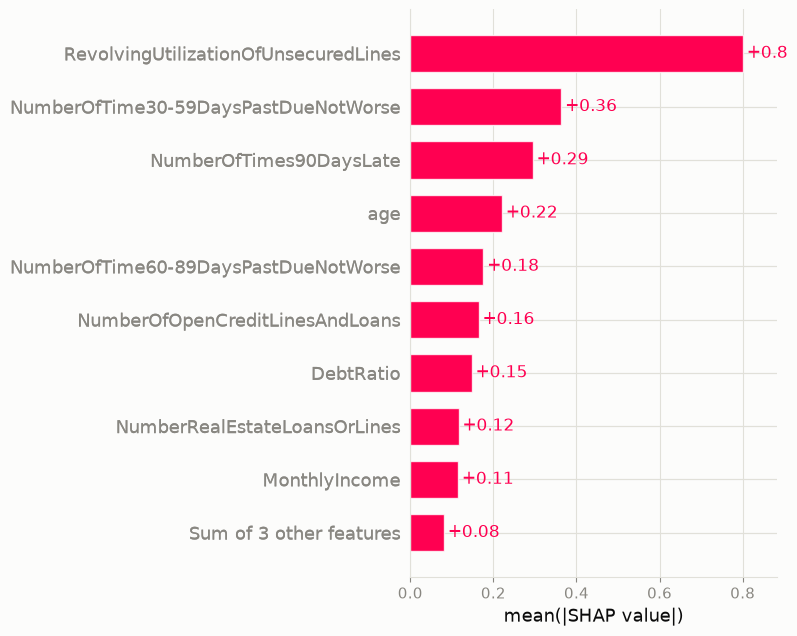

In [5]:
shap.plots.bar(shap_values, show=False)
plt.tight_layout()
plt.show()

### Confronto con XGBoost (gain), Random Forest e odds ratio della regressione logistica

Rialleniamo velocemente anche Random Forest e la regressione logistica (stessa configurazione dei
notebook 03/04) per avere, in un'unica tabella in questo notebook, tutti e quattro i ranking di
importanza fianco a fianco.

In [6]:
rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_SEED)
rf_model.fit(X_train, y_train)

X_train_c = sm.add_constant(X_train)
logit_result = sm.Logit(y_train, X_train_c).fit(disp=0)

delinq_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
]
binary_flags = ['MonthlyIncome_mancante', 'NumberOfDependents_mancante']

logit_effect = {}
for var in FEATURES:
    coef = logit_result.params[var]
    if var in binary_flags or var in delinq_cols:
        logit_effect[var] = abs(coef)
    else:
        iqr = X_train[var].quantile(0.75) - X_train[var].quantile(0.25)
        logit_effect[var] = abs(coef * iqr)

mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES)

importance_comparison = pd.DataFrame({
    'SHAP_mean_abs': mean_abs_shap,
    'XGBoost_gain': pd.Series(xgb_model.feature_importances_, index=FEATURES),
    'RandomForest_importance': pd.Series(rf_model.feature_importances_, index=FEATURES),
    'LogReg_effetto_scalato': pd.Series(logit_effect),
})
for col in list(importance_comparison.columns):
    importance_comparison[col + '_rank'] = importance_comparison[col].rank(ascending=False).astype(int)

importance_comparison.sort_values('SHAP_mean_abs', ascending=False).round(4)

,SHAP_mean_abs,XGBoost_gain,RandomForest_importance,LogReg_effetto_scalato,SHAP_mean_abs_rank,XGBoost_gain_rank,RandomForest_importance_rank,LogReg_effetto_scalato_rank
RevolvingUtilizationOfUnsecuredLines,0.8005,0.1560,0.1965,1.2262,1,4,1,1
NumberOfTime30-59DaysPastDueNotWorse,0.3632,0.1570,0.0830,0.3422,2,3,7,2
NumberOfTimes90DaysLate,0.2946,0.3737,0.1722,0.3077,3,1,2,4
age,0.2205,0.0222,0.0959,0.3300,4,7,5,3
NumberOfTime60-89DaysPastDueNotWorse,0.1756,0.1620,0.0908,0.2094,5,2,6,6
NumberOfOpenCreditLinesAndLoans,0.1645,0.0195,0.0707,0.1808,6,8,8,7
DebtRatio,0.1477,0.0173,0.1238,0.0001,7,10,3,12
NumberRealEstateLoansOrLines,0.1161,0.0277,0.0255,0.1696,8,5,10,8
MonthlyIncome,0.1148,0.0175,0.1070,0.0946,9,9,4,10
NumberOfDependents,0.0458,0.0146,0.0284,0.0626,10,11,9,11


**Convergenza:** `RevolvingUtilizationOfUnsecuredLines` e le colonne di ritardo pagamenti restano
in cima secondo **tutte e quattro** le misure — il segnale più solido del progetto, confermato per
la quarta volta con un metodo diverso (dopo notebook 02, 03 e 04).

**Una scoperta interessante: SHAP non è d'accordo nemmeno con la "gain importance" dello stesso
identico modello XGBoost.** `RevolvingUtilizationOfUnsecuredLines` è **1ª per SHAP ma solo 4ª per il
gain nativo di XGBoost**; `NumberOfTimes90DaysLate` è l'opposto (1ª per gain, 3ª per SHAP). Non è un
errore: il "gain" di un albero misura quanto si riduce l'errore nei punti in cui una variabile è
*usata per uno split*, un conteggio che può essere dominato da poche variabili scelte presto e
spesso dall'algoritmo, senza distribuire "il merito" in modo equo tra tutte le osservazioni. SHAP
(basato sui valori di Shapley, un concetto della teoria dei giochi) distribuisce il contributo in
modo assiomaticamente equo su tutte le combinazioni di variabili: per capire cosa guida *davvero*
le previsioni di un modello ad albero, conviene fidarsi di SHAP più che della sua importanza
nativa.

**`DebtRatio`: SHAP fa da arbitro tra Random Forest e regressione logistica.** Random Forest la
metteva 3ª (notebook 04), la regressione logistica quasi ultima (12ª, effetto trascurabile). SHAP
la colloca a metà classifica (7ª): più vicina alla lettura scettica della regressione logistica che
a quella di Random Forest, a supporto dell'ipotesi già avanzata nel notebook 04 che l'importanza
basata su impurity di Random Forest sovrastimi le variabili continue ad alta cardinalità come
`DebtRatio`.

**`NumberOfDependents_mancante`: l'unica vera discrepanza.** La regressione logistica le assegnava
un effetto relativamente marcato (5ª posizione, odds ratio ≈ 0,76), ma per SHAP è **l'ultima** delle
12 variabili (quasi zero impatto sulle previsioni di XGBoost). Probabile spiegazione: riguarda solo
il 2,6% dei clienti (si veda notebook 01_eda) e nella regressione logistica aveva già un intervallo
di confidenza piuttosto ampio (0,61-0,94, notebook 03) — un segnale statisticamente presente ma
non fortissimo in un modello lineare può semplicemente non emergere come utile in un insieme di
alberi, che deve "guadagnarsi" l'attenzione tramite split efficaci su un flag così raro.

## 4. Interpretabilità locale: tre clienti specifici

Scegliamo, tra i clienti del test set classificati a soglia 0,5, il caso **più netto** in ciascuna
delle tre categorie richieste (probabilità stimata più estrema nella rispettiva categoria), per
avere esempi il più possibile chiari da presentare:

- **Vero positivo**: PD più alta tra i clienti insolventi correttamente identificati come a rischio
- **Vero negativo**: PD più bassa tra i clienti non insolventi correttamente identificati come a
  basso rischio
- **Falso negativo**: PD più bassa tra i clienti insolventi **non** identificati dal modello — il
  caso in cui il modello si è sbagliato con più sicurezza, quindi il più istruttivo da analizzare
  (si veda nota sotto sul perché un falso negativo, non un falso positivo).

Nel nostro caso il tasso di falsi negativi è molto più alto di quello di falsi positivi (notebook
04: 1.588 contro 303, alla stessa soglia) ed è anche l'errore più costoso in un contesto di rischio
di credito (un cliente che va in default senza essere stato intercettato, rispetto a un buon
cliente sottoposto solo a una verifica in più): per questo scegliamo un falso negativo come
esempio.

In [7]:
results = pd.DataFrame({
    'proba': proba_test,
    'pred': (proba_test >= 0.5).astype(int),
    'actual': y_test.values,
}, index=X_test.index)

tp_idx = results[(results.actual == 1) & (results.pred == 1)]['proba'].idxmax()
tn_idx = results[(results.actual == 0) & (results.pred == 0)]['proba'].idxmin()
fn_idx = results[(results.actual == 1) & (results.pred == 0)]['proba'].idxmin()

selected = {'Vero Positivo': tp_idx, 'Vero Negativo': tn_idx, 'Falso Negativo': fn_idx}
for label, idx in selected.items():
    r = results.loc[idx]
    print(f"{label}: CustomerID={idx}  PD stimata={r.proba:.4f}  esito reale={int(r.actual)}")

X_selected = X_test.loc[list(selected.values())]
shap_selected = explainer(X_selected)

Vero Positivo: CustomerID=22556  PD stimata=0.9166  esito reale=1
Vero Negativo: CustomerID=90201  PD stimata=0.0009  esito reale=0
Falso Negativo: CustomerID=32517  PD stimata=0.0016  esito reale=1


### Caso 1 - Vero Positivo (alto rischio, previsione corretta)

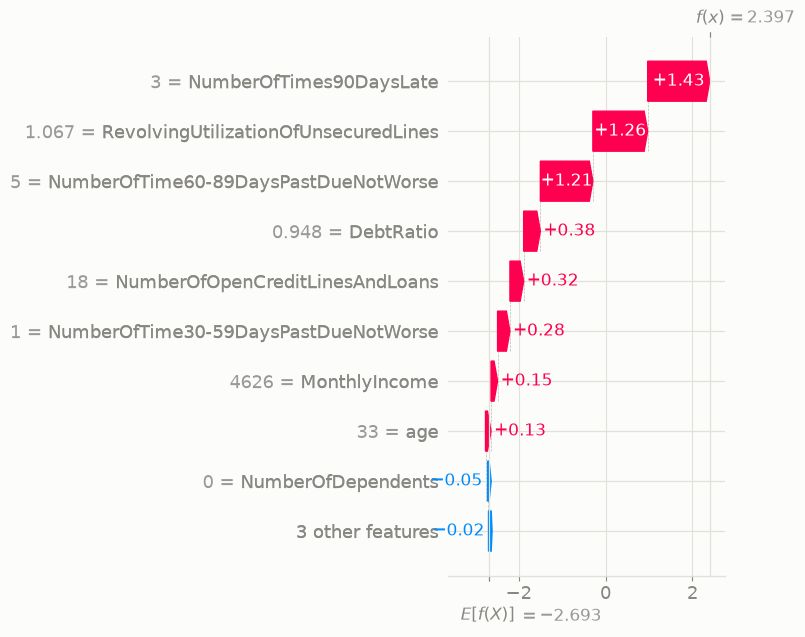

In [8]:
shap.plots.waterfall(shap_selected[0], show=False)
plt.tight_layout()
plt.show()

**In parole semplici:** il cliente è stato classificato ad alto rischio (probabilità di insolvenza
stimata **91,7%**) principalmente per **tre ritardi di pagamento gravi (90+ giorni) e cinque
ritardi intermedi (60-89 giorni)** già registrati, oltre a un **utilizzo delle linee di credito
revolving superiore al 100%** (già oltre il fido concesso) e a un rapporto debito/reddito quasi
triplo rispetto alla media dei clienti. Non c'è un solo segnale isolato: quasi tutti gli indicatori
di rischio disponibili puntano nella stessa direzione, rendendo questo un caso ad alto rischio senza
ambiguità.

### Caso 2 - Vero Negativo (basso rischio, previsione corretta)

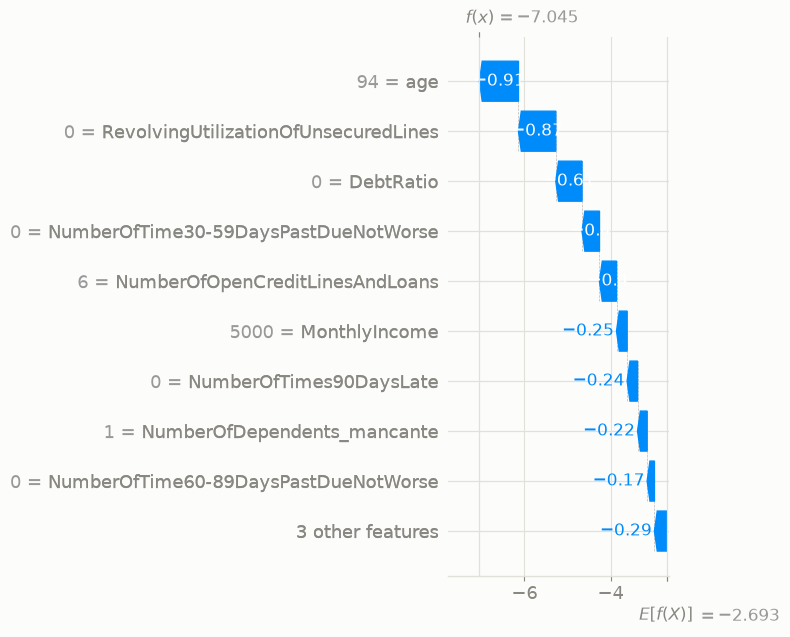

In [9]:
shap.plots.waterfall(shap_selected[1], show=False)
plt.tight_layout()
plt.show()

**In parole semplici:** probabilità di insolvenza stimata quasi nulla (**0,09%**). Il cliente ha
94 anni, **non utilizza affatto le linee di credito revolving** (utilizzo pari a zero) e ha un
rapporto debito/reddito pari a zero: un profilo creditizio molto conservativo, con nessun segnale
di attività finanziaria rischiosa su cui il modello possa basare un allarme.

### Caso 3 - Falso Negativo (il modello si è sbagliato)

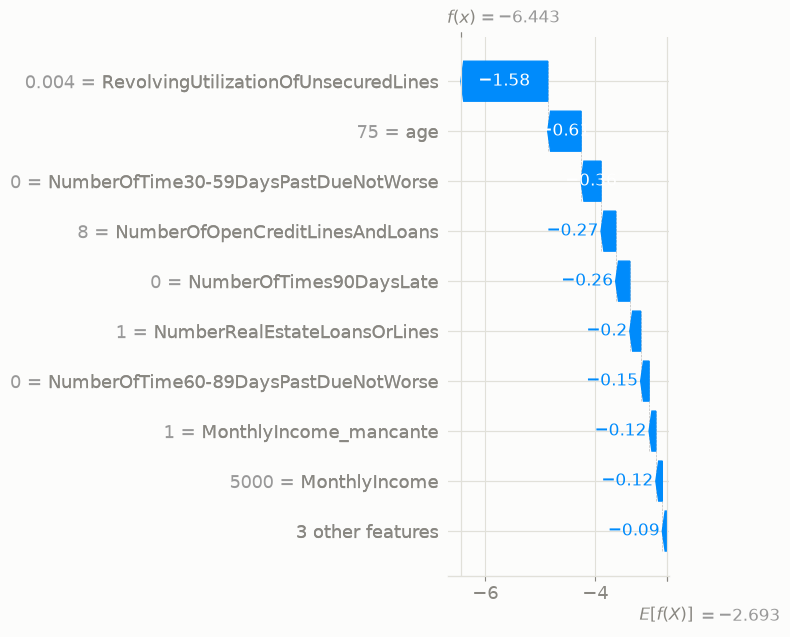

In [10]:
shap.plots.waterfall(shap_selected[2], show=False)
plt.tight_layout()
plt.show()

**In parole semplici — il caso più interessante.** Il modello ha stimato una probabilità di
insolvenza quasi nulla (**0,16%**) per questo cliente, che invece è andato in default. Guardando
SHAP capiamo *perché* si è sbagliato, non solo *che* si è sbagliato: il cliente ha 75 anni, un
**utilizzo delle linee di credito revolving praticamente a zero (0,4%)**, nessun ritardo di
pagamento pregresso in nessuna delle tre categorie, e un numero di linee di credito aperte e mutui
nella media. **Su carta è indistinguibile da un cliente a bassissimo rischio come nel Caso 2** —
ed è esattamente per questo che il modello lo ha classificato così. Il problema non è un errore del
modello nel senso di un calcolo sbagliato: è che questo dataset registra **comportamento
creditizio pregresso**, non eventi improvvisi (perdita del lavoro, spese mediche impreviste,
cambiamenti nella situazione familiare) che possono portare all'insolvenza un cliente con una
storia fino a quel momento ineccepibile. È un limite strutturale di qualunque modello basato solo su
dati storici di questo tipo, utile da comunicare esplicitamente a chi userà il punteggio per
decisioni di credito.

## 5. Salvataggio del ranking di importanza globale

In [11]:
importance_export = (
    mean_abs_shap
    .sort_values(ascending=False)
    .rename('mean_abs_shap_value')
    .reset_index()
    .rename(columns={'index': 'variabile'})
)
importance_export.insert(0, 'rank', range(1, len(importance_export) + 1))

OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'shap_importanza_globale.csv'
importance_export.to_csv(OUTPUT_PATH, index=False)

print(f"Salvato: {OUTPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}")
importance_export

Salvato: data/processed/shap_importanza_globale.csv


,rank,variabile,mean_abs_shap_value
0,1,RevolvingUtilizationOfUnsecuredLines,0.800505
1,2,NumberOfTime30-59DaysPastDueNotWorse,0.363229
2,3,NumberOfTimes90DaysLate,0.294619
3,4,age,0.220518
4,5,NumberOfTime60-89DaysPastDueNotWorse,0.175642
5,6,NumberOfOpenCreditLinesAndLoans,0.164484
6,7,DebtRatio,0.147728
7,8,NumberRealEstateLoansOrLines,0.116112
8,9,MonthlyIncome,0.114773
9,10,NumberOfDependents,0.045756


## Conclusioni

- SHAP conferma, con un quarto metodo indipendente, il nucleo di variabili già emerso nei notebook
  precedenti: `RevolvingUtilizationOfUnsecuredLines` e i ritardi di pagamento pregressi guidano le
  previsioni del modello più di ogni altra variabile.
- SHAP si è rivelato più affidabile della stessa "gain importance" nativa di XGBoost per capire cosa
  guida davvero il modello, e ha aiutato ad arbitrare le discrepanze tra Random Forest e regressione
  logistica su `DebtRatio` viste nel notebook 04.
- I tre casi locali mostrano che il modello **funziona come atteso quando i segnali di rischio sono
  storicamente presenti nei dati** (Casi 1 e 2), ma può mancare completamente casi di default privi
  di segnali pregressi (Caso 3) — un limite da comunicare a chi usa il punteggio, non da nascondere.
- Il ranking di importanza globale è salvato in `data/processed/shap_importanza_globale.csv` per la
  dashboard finale.